In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

Saving bozuk para.jpg to bozuk para.jpg


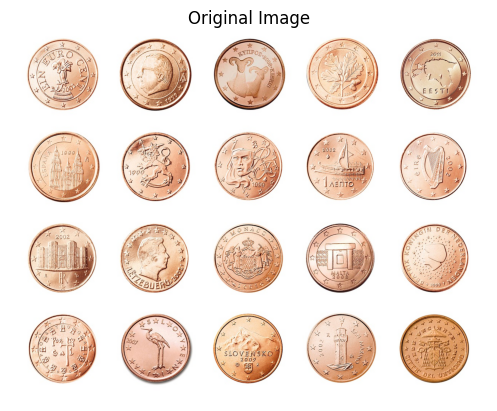

In [3]:
uploaded = files.upload()

filename = next(iter(uploaded))

img = cv2.imread(filename)

if img is None:
    raise ValueError("Goruntu okunamadi!")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()


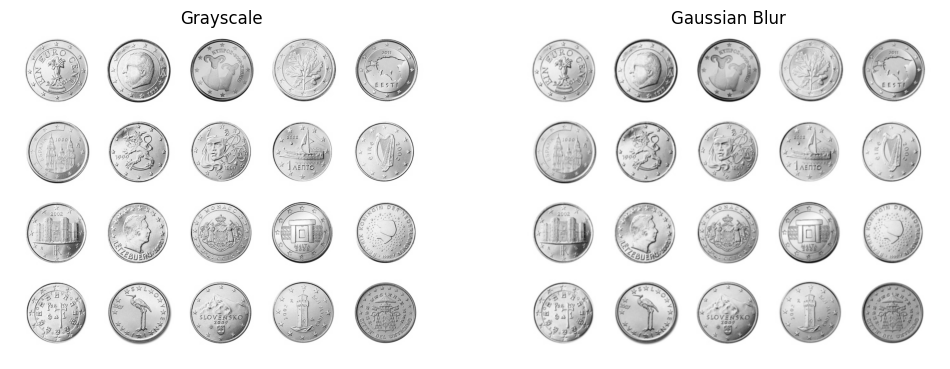

In [4]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(gray, (5, 5), 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(gray, cmap="gray")
axes[0].set_title("Grayscale")

axes[1].imshow(blur, cmap="gray")
axes[1].set_title("Gaussian Blur")

for ax in axes:
    ax.axis("off")

plt.show()


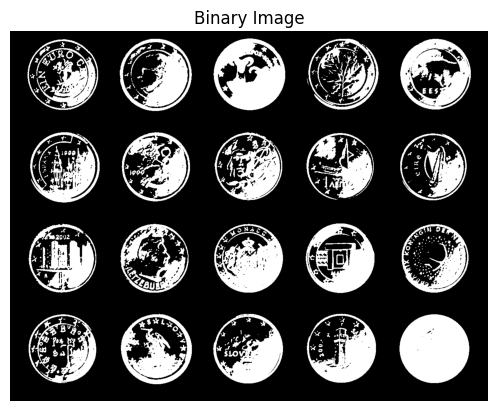

In [10]:

_, thresh = cv2.threshold(
    blur,
    0,
    255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

plt.imshow(thresh, cmap="gray")
plt.title("Binary Image")
plt.axis("off")
plt.show()


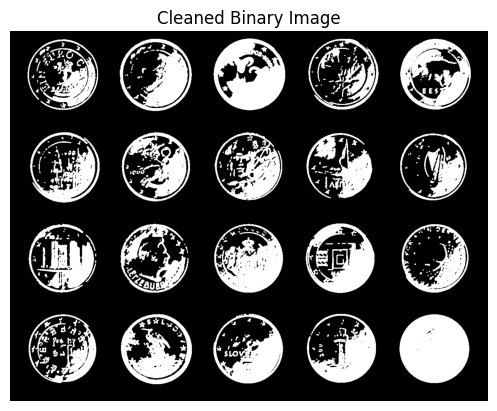

In [11]:
kernel = np.ones((3, 3), np.uint8)

cleaned = cv2.morphologyEx(
    thresh,
    cv2.MORPH_OPEN,
    kernel
)

plt.imshow(cleaned, cmap="gray")
plt.title("Cleaned Binary Image")
plt.axis("off")
plt.show()


In [12]:
contours, hierarchy = cv2.findContours(
    cleaned,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Bulunan kontur sayisi:", len(contours))


Bulunan kontur sayisi: 191


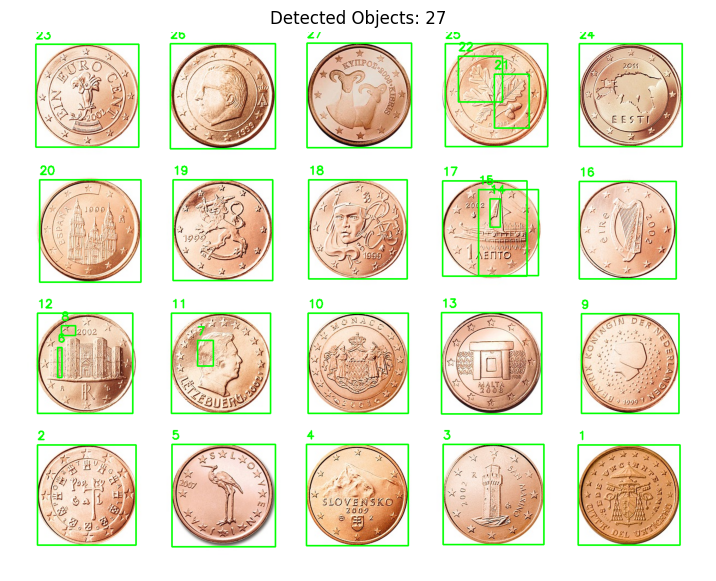

Total objects: 27


In [13]:
result = img_rgb.copy()

object_count = 0

for contour in contours:

    area = cv2.contourArea(contour)

    if area > 200:

        object_count += 1

        x, y, w, h = cv2.boundingRect(contour)

        cv2.rectangle(
            result,
            (x, y),
            (x + w, y + h),
            (0, 255, 0),
            2
        )

        cv2.putText(
            result,
            str(object_count),
            (x, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (0, 255, 0),
            2
        )

plt.figure(figsize=(10, 7))
plt.imshow(result)
plt.title(f"Detected Objects: {object_count}")
plt.axis("off")
plt.show()

print("Total objects:", object_count)
